## Fitting Data 


In [13]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [14]:
# Import data manual
t = np.array([
    1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5,
    6, 6.5, 7, 7.5, 8, 8.5, 9, 9.5, 10,
    20, 30, 40, 50, 60, 70
], dtype=float)

x = np.array([
    0, 0.008157, 0.040093, 0.090194, 0.150342,
    0.214610, 0.279168, 0.341687, 0.200843,
    0.455959, 0.506769, 0.553267, 0.595596,
    0.833990, 0.668723, 0.700091, 0.728385,
    0.753889, 0.776870, 0.963240, 0.992048,
    0.997904, 0.999361, 0.999782, 0.999919
], dtype=float)

# df=pd.read_csv('___')
# df[nama_column]


## Model Linier
#### x = At+C 

## Model rumus
### x=1-exp{-kt^n}


In [3]:
# Model Fitting

# model linier 
def model_linier(A,t,C):
    return A*t+C

# model rumus teori
def model_(t,k,n):
    return 1-np.exp(-k*t**n)


In [4]:
# parameter pada liner 
parameter, covariance = curve_fit(
    model_linier,
    t,
    x,
    p0=[0.02, 2.0],
    bounds=([0, 0], [np.inf, np.inf]),
    maxfev=100000
)
A,C=parameter
print(A,C)

0.013204860492447169 0.3562266701382554


In [5]:
# parameter pada rumus 
parameter, covariance = curve_fit(
    model_,
    t,
    x,
    p0=[0.02, 2.0],
    bounds=([0, 0], [np.inf, np.inf]),
    maxfev=100000
)
k, n = parameter
print (k,n)

0.019148916655464383 1.971236718292539


In [6]:
x_linier=[]
for i in t :
    x_=model_linier(A,i,C)
    
    x_linier.append(x_)

print (x_linier)

[np.float64(0.36943153063070255), np.float64(0.37603396087692614), np.float64(0.38263639112314973), np.float64(0.38923882136937327), np.float64(0.3958412516155969), np.float64(0.40244368186182045), np.float64(0.40904611210804404), np.float64(0.4156485423542676), np.float64(0.4222509726004912), np.float64(0.4288534028467148), np.float64(0.4354558330929384), np.float64(0.442058263339162), np.float64(0.4486606935853856), np.float64(0.45526312383160916), np.float64(0.4618655540778327), np.float64(0.46846798432405634), np.float64(0.4750704145702799), np.float64(0.48167284481650346), np.float64(0.48827527506272705), np.float64(0.6203238799871987), np.float64(0.7523724849116704), np.float64(0.8844210898361421), np.float64(1.0164696947606138), np.float64(1.1485182996850853), np.float64(1.2805669046095571)]


In [7]:
x_rumus =[]
for i in t :
    x_=model_(i,k,n)
    x_rumus.append(x_)
print(x_rumus)



[np.float64(0.0189667408273696), np.float64(0.04169147466079648), np.float64(0.07233415034426915), np.float64(0.11003014125973931), np.float64(0.15378303781938607), np.float64(0.20249897264610917), np.float64(0.2550261878431693), np.float64(0.3101959229095037), np.float64(0.3668618682774276), np.float64(0.42393604242478145), np.float64(0.4804194590761651), np.float64(0.5354264517744354), np.float64(0.5882020224673419), np.float64(0.6381320587967001), np.float64(0.6847466959190432), np.float64(0.7277174600550667), np.float64(0.7668491062071289), np.float64(0.8020672433061395), np.float64(0.8334029263288352), np.float64(0.9991125868501853), np.float64(0.9999998367319733), np.float64(0.9999999999989199), np.float64(1.0), np.float64(1.0), np.float64(1.0)]


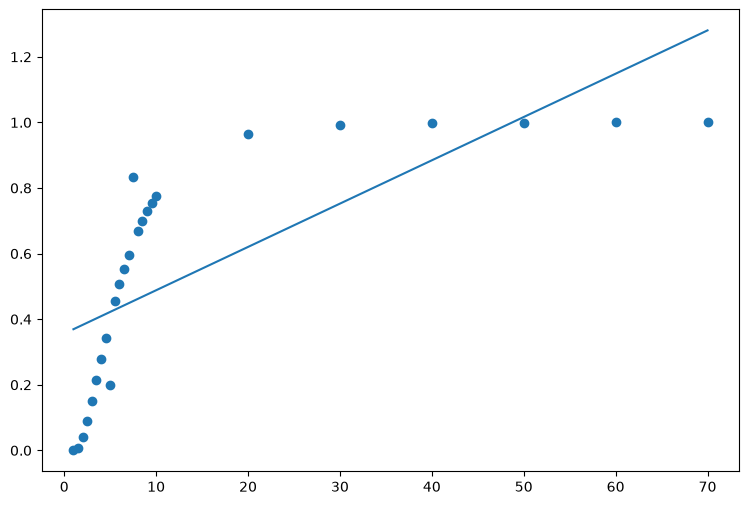

In [8]:
plt.figure(figsize=(9, 6))
plt.plot(t,x_linier)
plt.scatter(t,x,label='nama',marker ='o')

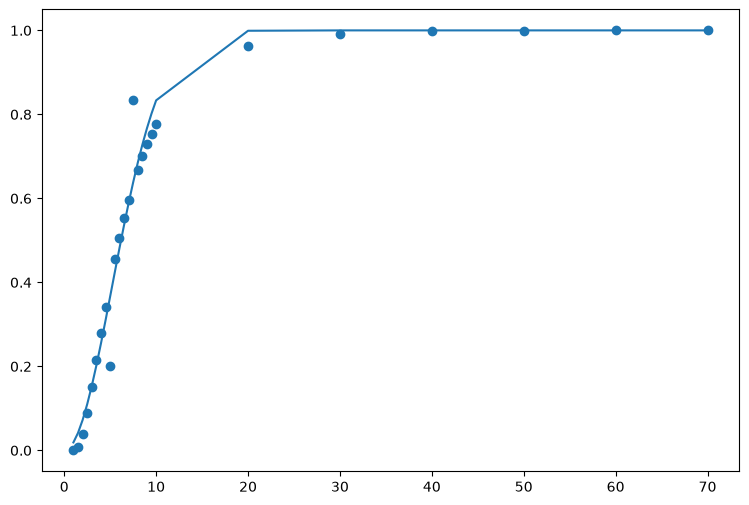

In [9]:
plt.figure(figsize=(9, 6))
plt.plot(t,x_rumus)
plt.scatter(t,x,label='nama',marker ='o')

In [10]:
# Menghitung nila R square
def residual_(x,x_):
    return x-x_

def R_2 (x,x_):
    residual = residual_(x,x_)
    SSE = np.sum(residual**2)
    SST = np.sum ((x -np.mean (x))**2)
    return 1- (SSE/SST)



In [11]:
# model linear
R_2_linier= R_2(x,x_linier)
print (R_2_linier)

0.5224172160153461


In [12]:
# model rumus 
R_2_rumus= R_2(x,x_rumus)
print (R_2_rumus)

0.9727121973072886
